<a href="https://colab.research.google.com/github/chanu2757/Data-Analysis-with-Open-Source/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_12%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 12강 정형 데이터 분석 : 서울시 공공 자전거 데이터 활용

### 목표

공공 자전거 이용 특성을 파악하고, 날씨와 자전거 이용량의 상관관계를 분석하여 데이터 기반의 정책 수립에 필요한 인사이트를 도출

### 분석 프로세스 개요

1. 데이터 수집 및 전처리
  - CSV 형태의 데이터 수집
  - 기초 통계량 산출
  - 결측치 처리 및 이상치 제거
  - 날짜/시간 데이터 형식 변환
2. 데이터 분석
  - 시계열 패턴 분석
3. 연계 분석
  - 강수량 데이터와의 연계 분석
  - 상관관계 분석
  - 정책 제언으로 연결

In [1]:
# 한글 처리를 위한 matplotlib 설정 (1)

!sudo apt-get install -y fonts-nanum
!sudo fc-cache –fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (10.0 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 127324 files and 

- 런타임 -> 세션 다시 시작

In [1]:
# 한글 처리를 위한 matplotlib 설정 (2)

import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

# 1. 데이터 수집 및 전처리

### 12-1 따릉이 대역 기록 2023-04 업로드 및 압축 해제

- 따릉이 데이터 다운로드
  - [서울 열린데이터 광장](https://data.seoul.go.kr)
  - 검색어 : 따릉이
  - 서울시 따릉이 대여소별 대여/반납 승객수 정보
  - 2023-04 다운로드 후 업로드

In [27]:
!unzip tpss_bcycl_od_statnhm_202610.zip -d tpss_bcycl_od_statnhm_202610

Archive:  tpss_bcycl_od_statnhm_202610.zip
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261015.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261018.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261016.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261019.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261017.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261010.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261011.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261013.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261014.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261012.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261004.csv  
  inflating: tpss_bcycl_od_statnhm_202610/tpss_bcycl_od_statnhm_20261005.csv  
  inflati

## 12-2 CSV 형태의 데이터 수집

In [28]:
import glob
import pandas as pd

## CSV 파일 목록 가져오기
all_files = glob.glob("tpss_bcycl_od_statnhm_202610/*.csv")
dataframes = []
for filename in all_files:
    ## CSV 파일 읽어서 데이터프레임화
    df = pd.read_csv(filename, encoding='cp949')
    dataframes.append(df)
## 모든 데이터프레임 결합
df = pd.concat(dataframes, axis=0, ignore_index=True)

## 상위 5행 출력
df.head(5)

,기준_날짜,집계_기준,기준_시간대,시작_대여소_ID,시작_대여소명,종료_대여소_ID,종료_대여소명,전체_건수,전체_이용_분,전체_이용_거리
0,20261029,출발시간,0,ST-1007,신월7동_013_1,ST-3304,신정4동_045_1,1,11.0,2558.0
1,20261029,출발시간,0,ST-1013,목3동_027_1,ST-2494,염창동_005_1,1,6.0,1037.0
2,20261029,출발시간,0,ST-1014,신정3동_091_1,ST-313,신월2동_009_1,1,48.0,10221.0
3,20261029,출발시간,0,ST-1041,성내1동_012_1,ST-503,성내1동_004_1,1,2.0,406.0
4,20261029,출발시간,0,ST-1064,발산1동_056_1,ST-2034,발산1동_001_2,1,4.0,713.0


In [9]:
df

,기준_날짜,집계_기준,기준_시간대,시작_대여소_ID,시작_대여소명,종료_대여소_ID,종료_대여소명,전체_건수,전체_이용_분,전체_이용_거리
0,20261108,출발시간,0,ST-1013,목3동_027_1,ST-1649,영등포동_025_1,1,27.0,9515.0
1,20261108,출발시간,0,ST-1015,목5동_002_1,ST-422,당산2동_003_2,1,21.0,1932.0
2,20261108,출발시간,0,ST-1017,목5동_008_1,ST-1018,목5동_051_1,1,NaN,NaN
3,20261108,출발시간,0,ST-1046,성내2동_010_1,ST-502,성내1동_014_1,1,6.0,1189.0
4,20261108,출발시간,0,ST-1065,가양1동_016_2,ST-2557,화곡6동_024_1,1,7.0,1311.0
...,...,...,...,...,...,...,...,...,...,...
56123,20261108,도착시간,2355,ST-705,난곡동_008_1,ST-702,신림동_006_1,1,9.0,1701.0
56124,20261108,도착시간,2355,ST-829,화곡1동_012_2,ST-2027,화곡1동_006_1,1,6.0,1851.0
56125,20261108,도착시간,2355,ST-857,중화1동_001_1,ST-2860,상봉1동_003_2,1,11.0,1434.0
56126,20261108,도착시간,2355,ST-913,월계1동_017_1,ST-2075,월계3동_003_1,1,6.0,1000.0


## 12-3 기초 통계량 산출

In [29]:
## 수치형 데이터 요약 통계 출력
print("수치형 데이터 요약 통계:\n", df.describe().to_markdown() )
## 범주형 데이터 요약 통계 출력
print("범주형 데이터 요약 통계:\n", df.describe(include=['object']).to_markdown())

수치형 데이터 요약 통계:
 |       |   기준_날짜 |    기준_시간대 |    전체_건수 |   전체_이용_분 |   전체_이용_거리 |
|:------|------------:|---------------:|-------------:|---------------:|-----------------:|
| count | 7.95526e+06 |    7.95526e+06 |  7.95526e+06 |    7.71255e+06 |      7.71255e+06 |
| mean  | 2.0261e+07  | 1438.63        |  1.06746     |   22.841       |   2615.16        |
| std   | 8.96788     |  551.798       |  0.292593    |   30.4501      |   3419.51        |
| min   | 2.0261e+07  |    0           |  1           |    1           |    300           |
| 25%   | 2.0261e+07  | 1010           |  1           |    6           |    890           |
| 50%   | 2.0261e+07  | 1540           |  1           |   12           |   1529           |
| 75%   | 2.0261e+07  | 1850           |  1           |   27           |   2861           |
| max   | 2.0261e+07  | 2355           | 18           | 1556           | 212892           |
범주형 데이터 요약 통계:
 |        | 집계_기준   | 시작_대여소_ID   | 시작_대여소명   | 종료_대여소_ID   | 종료_대여소명   |

## 12-4 결측치 및 이상치 제거

In [30]:
## 결측치 제거
df= df.dropna()
## '전체_이용_분' 컬럼 값 필터링 (1분 이하, 180분 이상 제거)
df = df[(df['전체_이용_분'] >1) & (df['전체_이용_분']<180)]
## '전체_이용_거리' 컬럼 값 필터링 (10M 이하, 10000M 이상 제거)
df = df[(df['전체_이용_거리']> 10) & (df['전체_이용_거리'] < 10000)]
## '집계_기준' 컬럼 필터링 (출발시간만 사용)
df = df[df['집계_기준'] == '출발시간']

In [16]:
## 수치형 데이터 요약 통계 출력
print("수치형 데이터 요약 통계:\n", df.describe().to_markdown() )
## 범주형 데이터 요약 통계 출력
print("범주형 데이터 요약 통계:\n", df.describe(include=['object']).to_markdown())

수치형 데이터 요약 통계:
 |       |       기준_날짜 |   기준_시간대 |    전체_건수 |   전체_이용_분 |   전체_이용_거리 |
|:------|----------------:|--------------:|-------------:|---------------:|-----------------:|
| count | 26161           |     26161     | 26161        |     26161      |         26161    |
| mean  |     2.02611e+07 |      1103.43  |     1.02974  |        16.8127 |          1955.94 |
| std   |     0           |       646.988 |     0.184124 |        20.4873 |          1697.15 |
| min   |     2.02611e+07 |         0     |     1        |         2      |           300    |
| 25%   |     2.02611e+07 |       650     |     1        |         6      |           843    |
| 50%   |     2.02611e+07 |      1055     |     1        |        10      |          1377    |
| 75%   |     2.02611e+07 |      1615     |     1        |        19      |          2380    |
| max   |     2.02611e+07 |      2355     |     7        |       178      |          9999    |
범주형 데이터 요약 통계:
 |        | 집계_기준   | 시작_대여소_ID   | 시작_대여소명

## 12-5 날짜/시간 데이터 형식 변환

In [31]:
## '기준_날짜' 컬럼 datetime 형식으로 변환 (%Y%m%d)
df['기준_날짜'] = pd.to_datetime(df['기준_날짜'], format="%Y%m%d")
## '요일' 컬럼 생성
day_mapping = {
    'Monday': '월요일',
    'Tuesday': '화요일',
    'Wednesday': '수요일',
    'Thursday': '목요일',
    'Friday': '금요일',
    'Saturday': '토요일',
    'Sunday': '일요일'
}
df['요일'] = df['기준_날짜'].dt.day_name().map(day_mapping)

## 전처리 결과 확인

In [32]:
## 수치형 데이터 요약 통계 출력
print("수치형 데이터 요약 통계:\n", df.describe().to_markdown())
## 범주형 데이터 요약 통계 출력
print("\n범주형 데이터 요약 통계:\n", df.describe(include=['object']).to_markdown())

수치형 데이터 요약 통계:
 |       | 기준_날짜                     |    기준_시간대 |    전체_건수 |   전체_이용_분 |   전체_이용_거리 |
|:------|:------------------------------|---------------:|-------------:|---------------:|-----------------:|
| count | 3681580                       |    3.68158e+06 |  3.68158e+06 |    3.68158e+06 |      3.68158e+06 |
| mean  | 2026-10-15 13:21:21.523259392 | 1419.87        |  1.05373     |   19.6042      |   2107.61        |
| min   | 2026-10-01 00:00:00           |    0           |  1           |    2           |    300           |
| 25%   | 2026-10-08 00:00:00           |  955           |  1           |    6           |    876           |
| 50%   | 2026-10-15 00:00:00           | 1525           |  1           |   11           |   1474           |
| 75%   | 2026-10-23 00:00:00           | 1835           |  1           |   24           |   2623           |
| max   | 2026-10-31 00:00:00           | 2355           | 17           |  179           |   9999           |
| std   | nan     

# 2. 데이터 분석

## 12-6 요일별 이용량 분석

In [33]:
## 요일별 이용량 계산 및 정렬
day_df = df['요일'].value_counts()
## 요일별 이용량 출력
print("요일별 이용량:\n", day_df)

요일별 이용량:
 요일
금요일    658266
목요일    648546
토요일    549531
수요일    507982
월요일    495839
화요일    484278
일요일    337138
Name: count, dtype: int64


## 12-7 요일별 이용량 시각화

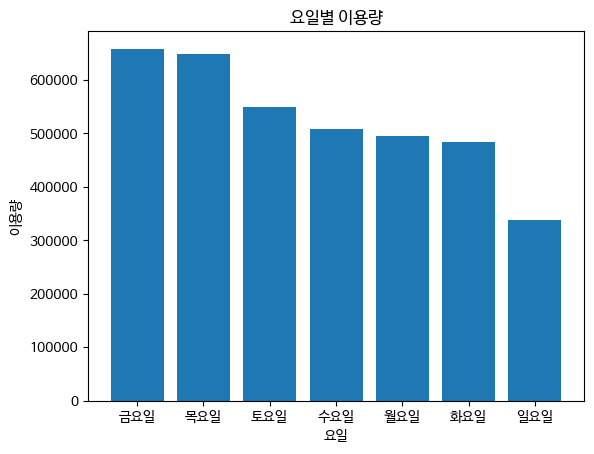

In [34]:
import matplotlib.pyplot as plt

## 요일별 이용량 막대 그래프 생성
plt.bar(day_df.index, day_df.values)
plt.title('요일별 이용량')
plt.xlabel('요일')
plt.ylabel('이용량')
plt.show()

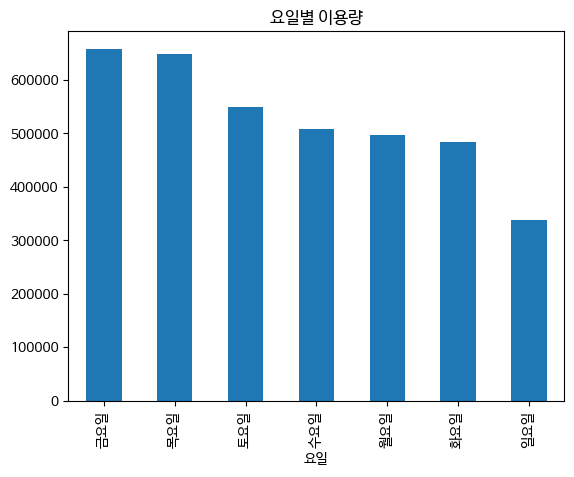

In [36]:
## Dataframe의 plot을 이용한 요일별 이용량 막대 그래프 생성
day_df.plot(kind='bar')
plt.title('요일별 이용량')
plt.show()

## 12-8 시간별 이용량 분석 및 시각화

시간별 이용량:
 출발_시
0      69227
1      46872
2      31792
3      23377
4      20505
5      39175
6      78889
7     185074
8     264532
9     166107
10    137669
11    157607
12    174539
13    173761
14    178057
15    201362
16    241974
17    315986
18    355608
19    239150
20    195729
21    173256
22    141916
23     69416
Name: count, dtype: int64


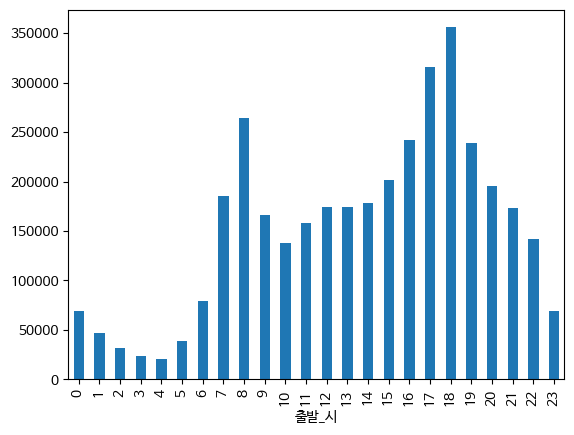

In [37]:
## '출발_시' 컬럼 생성 (기준_시간대 // 100)
df['출발_시'] = df['기준_시간대'] //100
## 시간별 이용량 계산 및 정렬 (hour_df로 저장)
hour_df = df['출발_시'].value_counts().sort_index()
## 시간별 이용량 출력
print("시간별 이용량:\n", hour_df)

## 시간별 이용량 막대 그래프 생성
hour_df.plot(kind='bar')
plt.show()

## 12-9 일자별 이용량 분석 및 시각화

일자별 이용량:
 기준_날짜
2026-10-01    146443
2026-10-02    146382
2026-10-03    111754
2026-10-04     96307
2026-10-05    103715
2026-10-06    140696
2026-10-07    145323
2026-10-08    146058
2026-10-09    112216
2026-10-10    118506
2026-10-11    108849
2026-10-12    134762
2026-10-13     86794
2026-10-14    138636
2026-10-15    135662
2026-10-16    143742
2026-10-17    119967
2026-10-18     32041
2026-10-19    129868
2026-10-20    136449
2026-10-21    107374
2026-10-22    122409
2026-10-23    133313
2026-10-24    100378
2026-10-25     99941
2026-10-26    127494
2026-10-27    120339
2026-10-28    116649
2026-10-29     97974
2026-10-30    122613
2026-10-31     98926
Name: count, dtype: int64


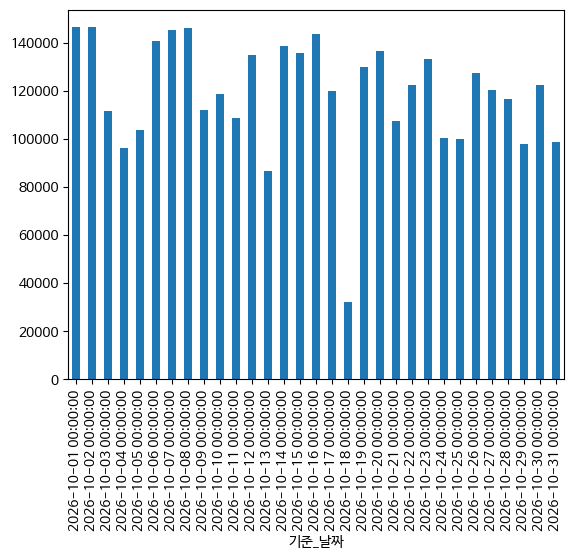

In [38]:
## 일자별 이용량 계산 및 정렬
daily_usage_df = df['기준_날짜'].value_counts().sort_index()
## 일자별 이용량 출력
print("일자별 이용량:\n", daily_usage_df)

## 일자별 이용량 막대 그래프 생성
daily_usage_df.plot(kind='bar')
plt.show()

# 3. 연계 분석

- 기상청 기상자료개방포탈 자료 수집
  - 기후통계분석 > 통계분석 > 조건별통계
  - https://data.kma.go.kr/climate/RankState/selectRankStatisticsDivisionList.do?pgmNo=179
  - 지역/지점 : 서울
  - 요소 : 강수량
  - 기간 : 일, 2023년 ~ 2023년
  - 조건 : 04월, 01 ~ 31일
- 다운로드 후 파일명 `seoul_rain_2023_04.csv`로 변경하여 colab에 업로드

## 12-10 강수량 데이터 로드

In [78]:
## 강수량 데이터 CSV 파일 로드
file_path = 'seoul_rain_2026_10.csv'
rain_df = pd.read_csv(file_path, encoding='cp949', skiprows=12)
rain_df.head(5)

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,\t지점번호,지점명,일시,강수량(mm),1시간최다강수량(mm),1시간최다강수량시각,Unnamed: 6
0,108,서울,2026-10-01,NaN,NaN,NaN,NaN
1,108,서울,2026-10-02,NaN,NaN,NaN,NaN
2,108,서울,2026-10-03,NaN,NaN,NaN,NaN
3,108,서울,2026-10-04,2.4,2.0,21:54,NaN
4,108,서울,2026-10-05,0.0,0.0,NaN,NaN


## 12-11 강수량 데이터 전처리

In [79]:
## '일시' 컬럼 datetime 형식으로 변환
rain_df['일시'] = pd.to_datetime(rain_df['일시'], format='%Y-%m-%d')
## '강수량(mm)' 컬럼 결측치 0으로 채우기
rain_df['강수량(mm)'] = rain_df['강수량(mm)'].fillna(0)
## 불필요한 컬럼 제거
rain_df.drop(columns=['\t지점번호', 'Unnamed: 6'], inplace=True)

In [80]:
rain_df

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,지점명,일시,강수량(mm),1시간최다강수량(mm),1시간최다강수량시각
0,서울,2026-10-01,0.0,NaN,NaN
1,서울,2026-10-02,0.0,NaN,NaN
2,서울,2026-10-03,0.0,NaN,NaN
3,서울,2026-10-04,2.4,2.0,21:54
4,서울,2026-10-05,0.0,0.0,NaN
5,서울,2026-10-06,0.0,NaN,NaN
6,서울,2026-10-07,0.0,NaN,NaN
7,서울,2026-10-08,0.0,NaN,NaN
8,서울,2026-10-09,0.0,NaN,NaN
9,서울,2026-10-10,0.0,NaN,NaN


## 12-12 일자별 이용량 데이터와 강수량 데이터 병합

In [81]:
## 일자별 이용량과 강수량 데이터 병합 (daily_usage_gf의 기준_날짜, rain_df의 일시를 기준으로 결합)
merged_df = pd.merge(daily_usage_df, rain_df, how='left', left_on='기준_날짜', right_on='일시')
## 'count' 컬럼명 '이용량'으로 변경
merged_df.rename(columns={'count': '이용량'}, inplace=True)
## 병합된 데이터프레임 상위 5행 출력
merged_df.head(5)

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,이용량,지점명,일시,강수량(mm),1시간최다강수량(mm),1시간최다강수량시각
0,146443,서울,2026-10-01,0.0,NaN,NaN
1,146382,서울,2026-10-02,0.0,NaN,NaN
2,111754,서울,2026-10-03,0.0,NaN,NaN
3,96307,서울,2026-10-04,2.4,2.0,21:54
4,103715,서울,2026-10-05,0.0,0.0,NaN


## 12-13 이용량 및 강수량 시각화

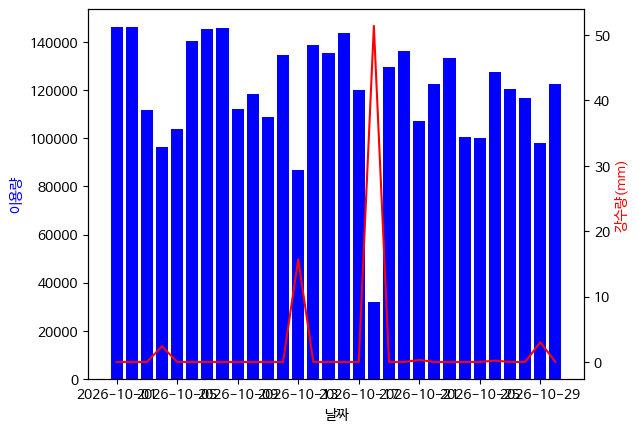

In [83]:
## 두 개의 y축을 가진 서브플롯 생성
fig, ax1 = plt.subplots()
ax2 = ax1.twinx() ## 두 번째 y축 생성

## 첫 번째 y축에 이용량 막대 그래프 그리기
ax1.bar(merged_df['일시'], merged_df['이용량'], color='b')
## 두 번째 y축에 강수량 꺾은선 그래프 그리기
ax2.plot(merged_df['일시'], merged_df['강수량(mm)'], color='r')

## x축 및 y축 레이블 설정
ax1.set_xlabel('날짜')
ax1.set_ylabel('이용량', color='b')
ax2.set_ylabel('강수량(mm)', color='r')

## 그래프 표시
plt.show()

## 12-14 강수량과 이용량 상관관계 분석

강수량과 이용량의 상관계수: -0.9526167003974472


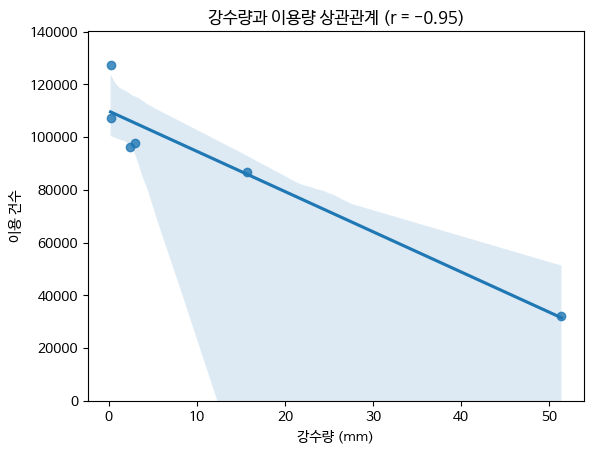

In [84]:
import seaborn as sns ## seaborn 라이브러리 임포트

## 강수량이 있는 날만 필터링
merged_onlyrain_df = merged_df[merged_df['강수량(mm)'] > 0]
## 강수량과 이용량의 상관계수 계산
corr = merged_onlyrain_df['이용량'].corr(merged_onlyrain_df['강수량(mm)'])
## 상관계수 출력
print("강수량과 이용량의 상관계수:", corr)

## 강수량과 이용량의 회귀선 그래프 생성
ax = sns.regplot(x='강수량(mm)', y='이용량', data=merged_onlyrain_df)

## y축 범위 설정
plt.ylim(0, merged_onlyrain_df['이용량'].max()*1.1)

## 그래프 제목 및 축 레이블 설정
plt.title(f'강수량과 이용량 상관관계 (r = {corr:.2f})')
plt.xlabel('강수량 (mm)')
plt.ylabel('이용 건수')
## 그래프 표시
plt.show()

## 12-15 OLS 회귀 모델 생성 및 분석 및 귀무가설 검증

In [85]:
import statsmodels.formula.api as smf ## statsmodels.formula.api 임포트

## 컬럼명 변경: '강수량(mm)' -> '강수량_mm' (formula API 호환을 위해)
merged_onlyrain_df = merged_onlyrain_df.copy()
merged_onlyrain_df.rename(columns={'강수량(mm)': '강수량_mm'}, inplace=True)

## OLS 모델 정의 및 학습
model = smf.ols(formula = '이용량 ~ 강수량_mm', data=merged_onlyrain_df)
results = model.fit()

## 모델 요약 결과 출력
print(results.summary())

## 귀무가설 검증 해석
## 강수량_mm 계수에 대한 p-value를 확인하여 귀무가설 (강수량이 이용량에 미치는 영향이 0이다) 검증
## 일반적으로 p-value가 0.05 미만이면 귀무가설을 기각하고 유의미한 영향이 있다고 해석
print("\n--- 귀무가설 검증 (강수량 계수) ---")
p_value = results.pvalues['강수량_mm']
print(f"강수량_mm 계수의 p-value: {p_value:.4f}")
if p_value < 0.05:
    print("p-value가 0.05보다 작으므로 귀무가설을 기각합니다.")
    print("즉, 강수량은 자전거 이용량에 통계적으로 유의미한 영향을 미칩니다.")
else:
    print("p-value가 0.05보다 크므로 귀무가설을 기각할 수 없습니다.")
    print("즉, 강수량은 자전거 이용량에 통계적으로 유의미한 영향을 미치지 않는다고 볼 수 있습니다.")

                            OLS Regression Results                            
Dep. Variable:                    이용량   R-squared:                       0.907
Model:                            OLS   Adj. R-squared:                  0.884
Method:                 Least Squares   F-statistic:                     39.23
Date:                Sat, 14 Nov 2026   Prob (F-statistic):            0.00331
Time:                        05:20:13   Log-Likelihood:                -63.096
No. Observations:                   6   AIC:                             130.2
Df Residuals:                       4   BIC:                             129.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.099e+05   5358.585     20.508      0.0

/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 6 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))
